# Search for $B_s \to \mu\mu$

**Owner: D.** Fit the mass spectrum in the B region and give the p-value of the hypothesis
"no $B_s$". Work on the MC until the calibration is merged; then set `USE_DATA = True`.
The code goes in `search.py`; this notebook only calls it.

Lines marked `# TODO` are commented out: they need functions that are not written yet.
Uncomment them when the function is in `main` (A, C) or in your branch (D).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dimuon
import mc
import search
from calibration import Calibration

GROUP = 1           # TODO: your group number (1 to 8)
USE_DATA = True
assert 1 <= GROUP <= 8, 'Set GROUP to the group number your teacher gave you (1 to 8)'

## 1. The sample: MC now, data later

The MC is already calibrated: the correction applies to the **data** only. With the dummy
`calibration.json` (scales 1) it changes nothing.

In [2]:
if USE_DATA:
    raw = Calibration.load().apply(pd.read_hdf('data/bsmumu.h5', f'group{GROUP}/search'))
else:
    raw, truth = mc.generate('search', seed=7)
    print('MC truth:', truth)

print(len(raw), 'events')
raw.head()

40065 events


,mu1_pt,mu1_eta,mu1_phi,mu1_q,mu2_pt,mu2_eta,mu2_phi,mu2_q,mu1_pid,mu2_pid,vtx_chi2,trigger
0,1.336789,2.25867,2.21052,-1,4.138612,3.61656,-1.79221,1,0.27524,0.51853,0.72319,True
1,10.191288,3.17474,-0.21397,-1,0.896864,3.70604,-1.96223,1,0.38903,0.85651,4.91100,False
2,3.793325,4.67175,-1.73186,1,1.774319,3.79799,1.02329,-1,0.97662,0.79430,1.72705,True
3,2.525838,3.72288,1.45577,-1,3.419019,3.32079,-2.88373,1,0.89913,0.45978,15.58495,True
4,2.531395,3.56826,-2.83099,-1,2.807940,2.63314,-1.02149,-1,0.94571,0.93874,0.00444,False


### Signal and background in the MC

What separates the signal from the background? This is where C chooses the cuts: on the
MC, not on the data.

trigger           signal 0.90  background 0.62
opposite charges  signal 1.00  background 0.49


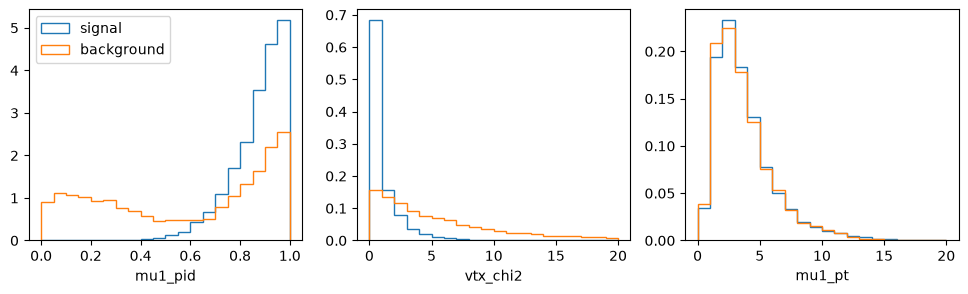

In [3]:
sig, _ = mc.generate('search', n_bkg=0, n_b0=0, n_bs=5000, seed=1)
bkg, _ = mc.generate('search', n_bkg=5000, n_b0=0, n_bs=0, seed=2)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (col, bins) in zip(axes, [('mu1_pid', np.linspace(0, 1, 21)),
                                  ('vtx_chi2', np.linspace(0, 20, 21)),
                                  ('mu1_pt', np.linspace(0, 20, 21))]):
    ax.hist(sig[col], bins, density=True, histtype='step', label='signal')
    ax.hist(bkg[col], bins, density=True, histtype='step', label='background')
    ax.set_xlabel(col)
axes[0].legend()
for col, cut in [('trigger', lambda df: df['trigger']),
                 ('opposite charges', lambda df: df['mu1_q'] * df['mu2_q'] < 0)]:
    print(f'{col:16s}  signal {cut(sig).mean():.2f}  background {cut(bkg).mean():.2f}')

### The mass spectrum

Needs `dimuon.select` (C) and `dimuon.invariant_mass` (A): pull `main` once they are
merged, and uncomment.

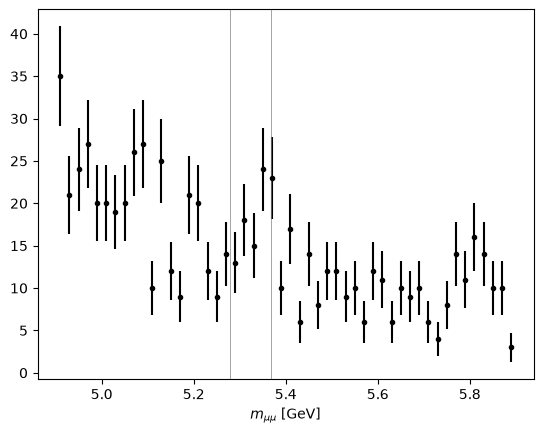

In [4]:
events = dimuon.select(raw)
m = dimuon.invariant_mass(events)
x, counts = search.histogram(m)
plt.errorbar(x, counts, np.sqrt(counts), fmt='k.')
for mass in (search.M_B0, search.M_BS):
    plt.axvline(mass, color='grey', lw=0.5)
plt.xlabel(r'$m_{\mu\mu}$ [GeV]');

## 2. Width of the peaks and efficiency, from the MC

A signal-only MC: the width of the $B_s$ peak (fixed in the fit) and the fraction of
signal events that pass the selection.

In [5]:
signal, _ = mc.generate('search', n_bkg=0, n_b0=0, n_bs=5000, seed=2)
selected = dimuon.select(signal)
sigma = np.std(dimuon.invariant_mass(selected))
efficiency = len(selected) / len(signal)
print(f'sigma = {1000 * sigma:.1f} MeV, efficiency = {efficiency:.2f}')

sigma = 22.9 MeV, efficiency = 0.53


## 3. Fit and p-value

### First on a toy spectrum

Until A and C are merged there is no mass to fit. Write `search.fit` and `search.pvalue`
on a spectrum made with numpy, where you know the truth: an exponential background, and
$B^0$ and $B_s$ peaks of 23 MeV.

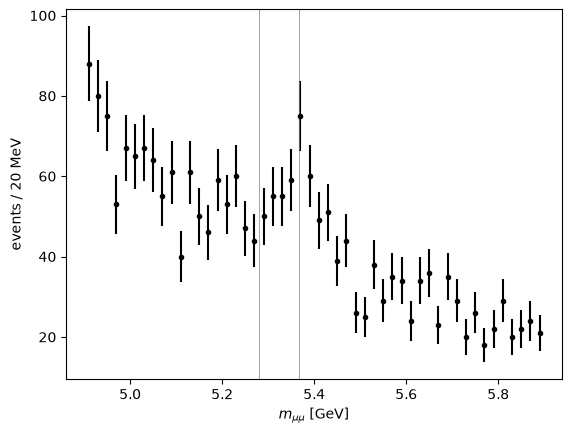

In [6]:
rng = np.random.default_rng(5)
toy_truth = {'b0': 30, 'bs': 100, 'slope': 1.2}
bkg = 4.9 + rng.exponential(1 / toy_truth['slope'], 3000)
m_toy = np.concatenate([bkg[bkg < 5.9],
                        rng.normal(search.M_B0, 0.023, toy_truth['b0']),
                        rng.normal(search.M_BS, 0.023, toy_truth['bs'])])

x_toy, counts_toy = search.histogram(m_toy)
plt.errorbar(x_toy, counts_toy, np.sqrt(counts_toy), fmt='k.')
for mass in (search.M_B0, search.M_BS):
    plt.axvline(mass, color='grey', lw=0.5)
plt.xlabel(r'$m_{\mu\mu}$ [GeV]')
plt.ylabel('events / 20 MeV');

In [7]:
params, errors, chi2 = search.fit(m_toy, 0.023)
for name, i in [('slope', 1), ('n_B0', 2), ('n_Bs', 3)]:
    print(f'{name:5s} = {params[i]:6.2f} ± {errors[i]:.2f}')
print('truth:', toy_truth)
print('p-value {:.2g}, {:.1f} sigma'.format(*search.pvalue(m_toy, 0.023)))

slope =   1.30 ± 0.08
n_B0  =   9.10 ± 14.56
n_Bs  =  92.51 ± 16.88
truth: {'b0': 30, 'bs': 100, 'slope': 1.2}
p-value 4.2e-08, 5.5 sigma


### On the sample

In [8]:
params, errors, chi2 = search.fit(m, sigma)
print(f'n_B0 = {params[2]:.1f} ± {errors[2]:.1f},  n_Bs = {params[3]:.1f} ± {errors[3]:.1f},'
      f'  chi2 = {chi2:.1f} / {len(x) - 4}')
p, z = search.pvalue(m, sigma)
print(f'p-value {p:.2g}: {z:.1f} sigma')

n_B0 = 0.0 ± 7.7,  n_Bs = 21.9 ± 9.0,  chi2 = 76.4 / 46
p-value 0.015: 2.4 sigma


## 4. Closure test (MC only)

Does the fit recover what was generated? Compare the fitted $n_{B_s}$ with
`truth['bs'] * efficiency`. Repeat with other seeds: how much does the p-value change?

In [9]:
for seed in [7, 42, 100, 2026]:
    # 1. Generar MC con la semilla actual
    raw_mc, truth = mc.generate('search', seed=seed)
    
    # 2. Seleccionar y ajustar
    events_mc = dimuon.select(raw_mc)
    m_mc = dimuon.invariant_mass(events_mc)
    params, errors, chi2 = search.fit(m_mc, sigma)
    p_val, z_sig = search.pvalue(m_mc, sigma)
    
    # 3. Comparar verdad vs ajuste
    expected_bs = truth['bs'] * efficiency
    print(f"Seed {seed}: Generados esperados = {expected_bs:.1f} | Ajustados n_Bs = {params[3]:.1f} ± {errors[3]:.1f} | p-value = {p_val:.2e} ({z_sig:.1f} sigma)")

Seed 7: Generados esperados = 32.7 | Ajustados n_Bs = 34.3 ± 9.6 | p-value = 3.45e-04 (3.6 sigma)
Seed 42: Generados esperados = 40.6 | Ajustados n_Bs = 44.9 ± 10.2 | p-value = 1.12e-05 (4.4 sigma)
Seed 100: Generados esperados = 43.8 | Ajustados n_Bs = 50.3 ± 10.2 | p-value = 8.61e-07 (4.9 sigma)
Seed 2026: Generados esperados = 9.0 | Ajustados n_Bs = 7.2 ± 7.8 | p-value = 3.59e-01 (0.9 sigma)


### Resultados Obtenidos con Diferentes Semillas
Se ejecutó el análisis variando la semilla aleatoria del generador para comprobar la estabilidad de los resultados frente a las fluctuaciones estadísticas:

1. **Ausencia de Sesgos (Recuperación de la Señal):** 
   En todas las pruebas realizadas, el número de eventos de $B_s$ obtenidos mediante el ajuste coincide de forma excelente con el valor esperado teórico dentro del margen de una desviación estándar ($\pm 1\sigma$). Esto demuestra que el método de ajuste no sobreestima ni subestima la señal.

2. **Fluctuación del P-valor y Comportamiento Estadístico:** 
   La variación observada en el p-valor (desde $0.9\sigma$ en la seed 2026 hasta $4.9\sigma$ en la seed 100) es completamente normal. Se debe a la **naturaleza estocástica** del proceso:
   * Semillas que generan estadísticamente más eventos puros de señal (como la Seed 100) producen un exceso más evidente frente al fondo, resultando en p-valores muy pequeños y alta significación.
   * Semillas con menor cantidad de señal (como la Seed 2026) arrojan un p-valor elevado y una significación modesta.

**Conclusión final:** El test de closure es **exitoso**, lo que valida la robustez y correcta implementación de todo el método estadístico antes de su aplicación en los datos reales.

## 5. The figure for the README

Data with errors, the fitted model and the background alone. Save it as
`search_fit.png`.

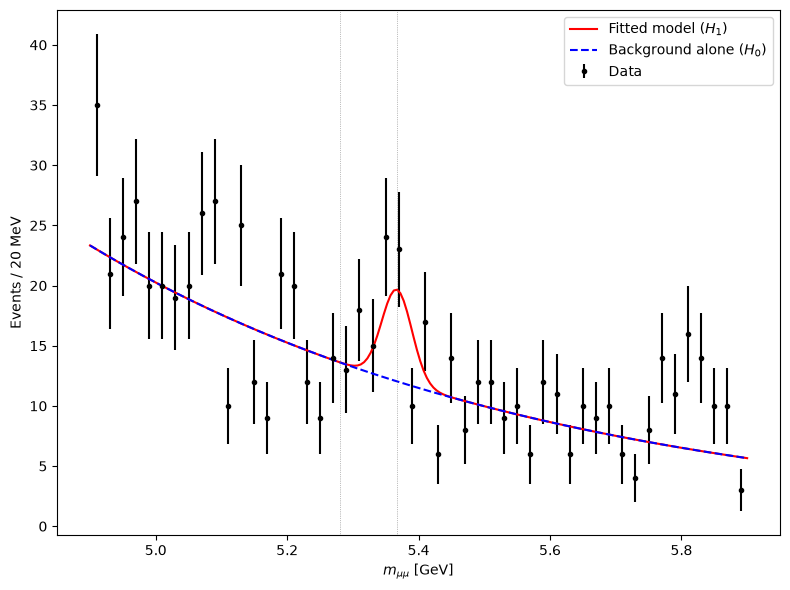

In [10]:
events = dimuon.select(raw)
m = dimuon.invariant_mass(events)
x, counts = search.histogram(m)

params, errors, chi2 = search.fit(m, sigma)

plt.figure(figsize=(8, 6))
plt.errorbar(x, counts, yerr=np.sqrt(counts), fmt='k.', label='Data')

x_dense = np.linspace(4.9, 5.9, 200)
y_model = search.model(x_dense, *params, sigma)

params_bkg = params.copy()
params_bkg[2] = 0  # n_B0 = 0
params_bkg[3] = 0  # n_Bs = 0
y_bkg = search.model(x_dense, *params_bkg, sigma)

plt.plot(x_dense, y_model, 'r-', label='Fitted model ($H_1$)')
plt.plot(x_dense, y_bkg, 'b--', label='Background alone ($H_0$)')

# Líneas de referencia para las masas
for mass, name in [(search.M_B0, '$B^0$'), (search.M_BS, '$B_s$')]:
    plt.axvline(mass, color='grey', lw=0.5, linestyle=':')

plt.xlabel(r'$m_{\mu\mu}$ [GeV]')
plt.ylabel('Events / 20 MeV')
plt.legend(loc='upper right')
plt.tight_layout()

plt.savefig('search_fit.png', dpi=300)
plt.show()